# SecondLook | 06 Path to approval

**Goal:** for every applicant the model would not approve, find the **smallest realistic change to the loan** that brings the re-scored risk under the cutoff, or say honestly that no such change exists.

This answers the second half of our business question: *"...and what realistic changes would get the rest approved?"*

**Method in one line:** change only the loan (borrow less, or spread it over more payments), recompute the features that depend on it, re-score with the same trained model, and keep the options that come out under the cutoff.

**Why only the loan?** The applicant can't change their credit history overnight, and we must never suggest changing personal traits (age, family). The loan amount and the number of payments are what a loan officer and an applicant can actually renegotiate. In Step 5 we tagged these as the **actionable** features.

**The levers** (in `src/secondlook/path.py`):
- **Borrow less:** cut the loan amount by 5% to 40%, in 5% steps.
- **Longer term:** multiply the number of payments by 1.1 to 1.5, capped at what approved applicants typically get (Section 3). Revolving loans (credit lines) have no fixed term, so they only get amount cuts.
- A change must bring the PD at least **0.5 points under the cutoff** (below 0.165), so an offer never hinges on the third decimal place.
- **Recommended option:** the smallest total change (a 10% cut counts the same as a 10% longer term); expected profit only breaks ties.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "secondlook").exists())
sys.path.insert(0, str(ROOT / "src"))

from secondlook.config import FIGURES_DIR, ID_COL, TARGET_COL, PROCESSED_DIR
from secondlook.features import load_features
from secondlook import modeling as M
from secondlook.letters import decision_for
from secondlook.path import (CUTS, TERM_MULTS, TERM_CAP, MARGIN, LOAN_FEATURES, apply_terms, score_grid,
                             summarise, path_to_approval)

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")

## 2. Load the model and the test set

Same model, same seed, same test split as Steps 4 and 5. We confirm the predictions match the saved ones exactly, then label every test applicant with the Phase 1 decision rule: approve under PD 0.17, **under review** from 0.17 to 0.22, decline above.

In [2]:
model, meta = M.load_model()
df = load_features()
train, test = M.split(df)
feats, cats, categories = meta["features"], meta["categorical"], meta["categories"]
cutoff = meta["cutoff"]

pd_test = model.predict_proba(M.prepare_X(test, feats, cats, categories))[:, 1]
saved = pd.read_parquet(PROCESSED_DIR / "test_predictions.parquet")
assert (saved[ID_COL].values == test[ID_COL].values).all() and np.allclose(saved["PD_LGBM"], pd_test)

test = test.assign(PD=pd_test, DECISION=[decision_for(p, cutoff) for p in pd_test])
print(f"Cutoff: PD {cutoff}   Under-review band: PD {meta['borderline_band'][0]}-{meta['borderline_band'][1]}")
print(test["DECISION"].value_counts().to_string())
borderline = test[test["DECISION"] == "under_review"]
declined = test[test["DECISION"] == "decline"]

Cutoff: PD 0.17   Under-review band: PD 0.17-0.22
DECISION
approve         54240
decline          4652
under_review     2611


## 3. How long can a loan realistically be?

A longer term lowers the regular payment, but we can't stretch a loan forever. We cap the number of payments at the **95th percentile among approved training applicants**: 95% of the loans the model approves are no longer than this. The value is stored in `path.py` as `TERM_CAP`, and the `assert` below checks the stored value against the data.

`CREDIT_TERM` is loan amount ÷ regular payment, which is roughly the number of monthly payments.

In [3]:
pd_train = model.predict_proba(M.prepare_X(train, feats, cats, categories))[:, 1]
approved_train = train[pd_train < cutoff]
p95 = approved_train["CREDIT_TERM"].quantile(0.95)
print(f"Approved training applicants: {len(approved_train):,}")
print("Number of payments (CREDIT_TERM) among them:")
print(approved_train["CREDIT_TERM"].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(1).to_string())
print(f"\n95th percentile: {p95:.1f}   TERM_CAP in path.py: {TERM_CAP}")
assert round(p95, 1) == TERM_CAP
print(f"Borderline applicants already above the cap: {(borderline['CREDIT_TERM'] > TERM_CAP).mean():.1%}")
print(f"Borderline applicants with a revolving loan (amount cuts only): {(borderline['NAME_CONTRACT_TYPE'] == 'Revolving loans').mean():.1%}")

Approved training applicants: 215,912
Number of payments (CREDIT_TERM) among them:
0.050    9.500
0.250   16.300
0.500   20.000
0.750   27.700
0.950   34.700

95th percentile: 34.7   TERM_CAP in path.py: 34.7
Borderline applicants already above the cap: 2.3%
Borderline applicants with a revolving loan (amount cuts only): 5.2%


## 4. Sanity checks before trusting any result

Two things must hold, or every path below is meaningless:
1. **Re-scoring an unchanged loan gives exactly the same PD** as the model's original prediction. If not, our feature recomputation differs from how the features were built.
2. **Only the loan features change.** A 20% cut with a 30% longer term must touch the six loan-term features and nothing else.

Both pass: the difference is exactly 0, and only the six loan features changed.

In [4]:
cols = [c for c in test.columns if c not in ("PD", "DECISION")]
unchanged = apply_terms(borderline[cols], cut=0.0, term_mult=1.0)
pd_again = model.predict_proba(M.prepare_X(unchanged, feats, cats, categories))[:, 1]
print(f"Max difference after re-scoring unchanged loans: {np.abs(pd_again - borderline['PD']).max():.1e}")

example = apply_terms(borderline[cols].iloc[[0]], cut=0.2, term_mult=1.3)
changed = [c for c in cols if not (borderline[cols].iloc[[0]][c].fillna(-999).values == example[c].fillna(-999).values).all()]
print("Features changed by a 20% cut and a 30% longer term:", changed)
assert set(changed) <= set(LOAN_FEATURES)

Max difference after re-scoring unchanged loans: 0.0e+00


Features changed by a 20% cut and a 30% longer term: ['AMT_CREDIT', 'AMT_ANNUITY', 'CREDIT_TO_INCOME', 'ANNUITY_TO_INCOME', 'CREDIT_TO_GOODS', 'CREDIT_TERM']


## 5. How much change does it take? (all 2,611 borderline applicants)

We re-score every borderline applicant under every combination of cut and term (up to 54 options each) and show the share that comes out under PD 0.165.

Note: longer terms are only possible for some applicants. Applicants whose loan is already near the cap, or who have revolving loans, drop out of the longer rows (the counts are printed under the chart). Each cell is the share of applicants **for whom that option is realistic**.

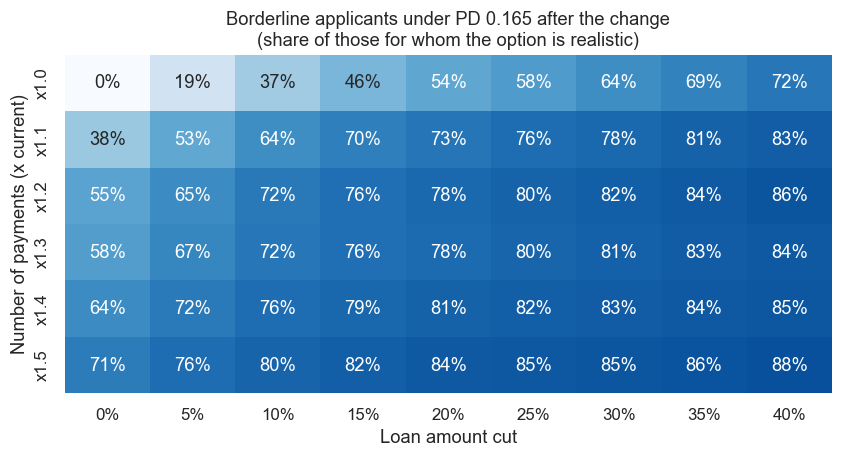

Applicants for whom each longer-term option is realistic (under the cap, not revolving):
term_mult
1.000    2611
1.100    2242
1.200    2084
1.300    1991
1.400    1855
1.500    1781


In [5]:
grid_b = score_grid(borderline[cols], model, meta)
share = (grid_b.assign(approved=grid_b["pd"] < cutoff - MARGIN)
         .pivot_table(index="term_mult", columns="cut", values="approved", aggfunc="mean"))
n_options = grid_b.groupby(["term_mult", "cut"]).size().unstack()

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(share, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
            xticklabels=[f"{c:.0%}" for c in share.columns], yticklabels=[f"x{m:.1f}" for m in share.index])
ax.set_xlabel("Loan amount cut"); ax.set_ylabel("Number of payments (x current)")
ax.set_title(f"Borderline applicants under PD {cutoff - MARGIN:.3f} after the change\n(share of those for whom the option is realistic)")
save(fig, "25_path_grid"); plt.show()
print("Applicants for whom each longer-term option is realistic (under the cap, not revolving):")
print(n_options.iloc[:, 0].rename("applicants").to_string())

**Interpretation:**
- **Small changes go a long way.** Keeping the term, a 10% smaller loan brings 37% of borderline applicants under the line, and a 20% cut brings 54%.
- **The term matters at least as much as the amount.** A 10% longer term on the full amount works for 38% of those who can have it; 20% longer works for 55%.
- **Combining both helps most:** a 20% cut with a 20% longer term works for 78%.
- This is the model's view. Why a longer term lowers risk is discussed in Section 6 and the limitations.

## 6. Does the model move in a sensible direction?

Before suggesting changes, we check that the model agrees with common sense on average: a smaller loan, or the same loan spread over more payments, should not *raise* risk. We also count how often it does for individual applicants. A tree model can be bumpy, so the search must re-score every option instead of assuming a direction.

For the longer-term line we use only the 1,781 applicants for whom every term option is realistic, so each point averages the same people.

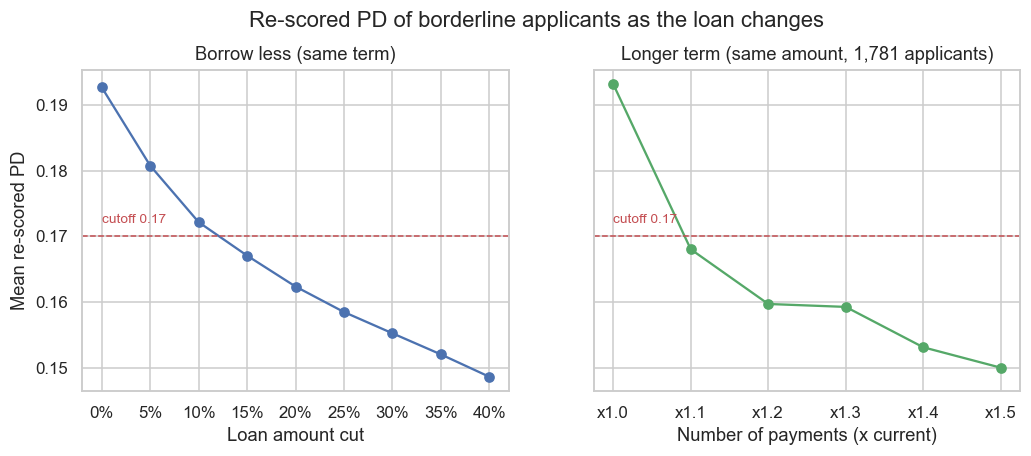

Borrow less:
       mean_pd  share_pd_up
cut                        
0.000    0.193        0.000
0.050    0.181        0.123
0.100    0.172        0.083
0.150    0.167        0.065
0.200    0.162        0.051
0.250    0.159        0.047
0.300    0.155        0.035
0.350    0.152        0.030
0.400    0.149        0.026

Longer term:
           mean_pd  applicants  share_pd_up
term_mult                                  
1.000        0.193        1781        0.000
1.100        0.168        1781        0.224
1.200        0.160        1781        0.136
1.300        0.159        1781        0.137
1.400        0.153        1781        0.112
1.500        0.150        1781        0.097


In [6]:
base = grid_b[(grid_b["cut"] == 0) & (grid_b["term_mult"] == 1.0)].set_index(ID_COL)["pd"]
g = grid_b.join(base.rename("pd_now"), on=ID_COL)
by_cut = g[g["term_mult"] == 1.0].groupby("cut").agg(mean_pd=("pd", "mean"),
                                                   share_pd_up=("pd", lambda s: (s > g.loc[s.index, "pd_now"] + 1e-9).mean()))
# Longer terms are not open to everyone (cap, revolving loans): compare like with like, using only
# applicants for whom every term option up to x1.5 is realistic
full = g.loc[(g["cut"] == 0) & (g["term_mult"] == max(TERM_MULTS)), ID_COL]
by_term = g[(g["cut"] == 0) & g[ID_COL].isin(full)].groupby("term_mult").agg(mean_pd=("pd", "mean"), applicants=("pd", "size"),
                                                   share_pd_up=("pd", lambda s: (s > g.loc[s.index, "pd_now"] + 1e-9).mean()))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
axes[0].plot([f"{c:.0%}" for c in by_cut.index], by_cut["mean_pd"], marker="o")
axes[0].set_title("Borrow less (same term)"); axes[0].set_xlabel("Loan amount cut"); axes[0].set_ylabel("Mean re-scored PD")
axes[1].plot([f"x{m:.1f}" for m in by_term.index], by_term["mean_pd"], marker="o", color="C2")
axes[1].set_title(f"Longer term (same amount, {len(full):,} applicants)"); axes[1].set_xlabel("Number of payments (x current)")
for ax in axes:
    ax.axhline(cutoff, color="C3", ls="--", lw=1); ax.text(0, cutoff + 0.002, f"cutoff {cutoff}", color="C3", fontsize=9)
fig.suptitle("Re-scored PD of borderline applicants as the loan changes", y=1.02)
save(fig, "26_path_direction"); plt.show()
print("Borrow less:"); print(by_cut.to_string(float_format="{:.3f}".format))
print("\nLonger term:"); print(by_term.to_string(float_format="{:.3f}".format))

**Interpretation:**
- **On average both levers lower risk.** Mean PD falls from 0.193 to 0.149 with a 40% smaller loan, and to 0.150 with a 50% longer term.
- **Not for every applicant.** A 5% cut raises the PD for 12.3% of applicants, and a 10% longer term raises it for 22.4%. These shares fall as the change grows (2.6% at a 40% cut, 9.7% at ×1.5).
- **Why that matters:** a rule like "just lend 10% less" would sometimes make things worse. `path.py` re-scores every option and only keeps the ones that really come out under the line.
- **Why would a longer term lower risk?** A smaller regular payment is easier to afford (lower repayment vs income). But the model also learned from history, where lenders tended to give longer terms to customers they already trusted. Part of the term effect may be that selection, not cause. This is why the recommended option treats a longer term as a change of the same size as a cut, rather than stretching every loan to the maximum.

## 7. Path to approval for every under-review and declined applicant

Now the real search: for each applicant, the smallest cut that works on its own, the shortest term increase that works on its own, and the recommended option (the smallest change, any combination).

In [7]:
grid_d = score_grid(declined[cols], model, meta)
summary = {}
for name, grid, group in [("Under review", grid_b, borderline), ("Declined", grid_d, declined)]:
    s = summarise(grid, cutoff).merge(group[[ID_COL, TARGET_COL]], on=ID_COL)
    summary[name] = s
    print(f"{name}: {len(s):,} applicants")
    print(f"  any path to approval:          {s['has_path'].mean():.1%}")
    print(f"  by borrowing less alone:       {s['borrow_less_cut'].notna().mean():.1%}"
          f"   (median cut {s['borrow_less_cut'].median():.0%})")
    print(f"  by a longer term alone:        {s['longer_term_mult'].notna().mean():.1%}"
          f"   (median x{s['longer_term_mult'].median():.1f})")
    print(f"  only by combining both:        {(s['has_path'] & s['borrow_less_cut'].isna() & s['longer_term_mult'].isna()).mean():.1%}")
    print(f"  no path within 40% / x1.5:     {(~s['has_path']).mean():.1%}")
    rec = s[s["has_path"]]
    print(f"  recommended option keeps the full amount: {(rec['rec_cut'] == 0).mean():.1%};"
          f" keeps the term: {(rec['rec_term_mult'] == 1.0).mean():.1%}\n")

Under review: 2,611 applicants
  any path to approval:          90.1%
  by borrowing less alone:       74.2%   (median cut 10%)
  by a longer term alone:        62.4%   (median x1.1)
  only by combining both:        5.6%
  no path within 40% / x1.5:     9.9%
  recommended option keeps the full amount: 35.0%; keeps the term: 50.8%

Declined: 4,652 applicants
  any path to approval:          31.3%
  by borrowing less alone:       9.0%   (median cut 28%)
  by a longer term alone:        10.7%   (median x1.3)
  only by combining both:        16.2%
  no path within 40% / x1.5:     68.7%
  recommended option keeps the full amount: 17.1%; keeps the term: 10.9%



**Interpretation:**
- **Borderline applicants (under review): 90.1% have a realistic path.** 74.2% can get there by borrowing less alone (typically 10% less), and 62.4% by a longer term alone (typically 10% more payments). Only 9.9% have no path within a 40% cut and 50% longer term.
- **Declined applicants: 31.3% have a path**, but it takes much bigger changes (a typical 28% cut), and half of those need both levers. For 68.7%, no change to the loan is enough: the risk comes from their history, not the loan.
- **The recommended option is usually modest:** for borderline applicants it keeps the original term in 50.8% of cases and the full amount in 35.0%.
- This is exactly SecondLook's point: for the borderline group, the question is usually not *whether* to lend, but *how much and over how long*.

## 8. Do the applicants with a path actually repay?

The test data tells us what really happened to each applicant (with their **original** loan). This doesn't prove the new terms would work, but it shows whether the path picks out people who are good risks.

In [8]:
rows = []
for name, s in summary.items():
    for has, part in s.groupby("has_path"):
        rows.append({"Group": name, "Has a path": "yes" if has else "no", "Applicants": len(part),
                     "Actually repaid": 1 - part[TARGET_COL].mean()})
outcome = pd.DataFrame(rows)
approved_default = test.loc[test["DECISION"] == "approve", TARGET_COL].mean()
print(outcome.to_string(index=False, formatters={"Applicants": "{:,}".format, "Actually repaid": "{:.1%}".format}))
print(f"For comparison, approved applicants repaid {1 - approved_default:.1%} of the time.")

       Group Has a path Applicants Actually repaid
Under review         no        259           79.5%
Under review        yes      2,352           79.8%
    Declined         no      3,196           63.9%
    Declined        yes      1,456           72.7%
For comparison, approved applicants repaid 94.7% of the time.


**Interpretation:**
- **Among borderline applicants, having a path doesn't separate good from bad:** 79.8% of those with a path repaid, vs 79.5% of those without. Almost the whole group is close to the line, so a path exists for nearly everyone. The value here is turning a "no" into a smaller or longer "yes" for the roughly 4 in 5 who repaid.
- **Among declined applicants, it does:** those with a path repaid 72.7% of the time, vs 63.9% for those without. The search picks out declined applicants whose risk comes mainly from the size or shape of the loan.
- **Both groups repaid less often than approved applicants (94.7%).** That is why the path goes to a loan officer as a suggestion, not as an automatic approval.

## 9. Three applicants, three outcomes

What a loan officer would see for one applicant who can borrow less, one who only needs a longer term, and one declined applicant with no realistic path.

In [9]:
s = summary["Under review"]
picks = {
    "borrow less": s[s["borrow_less_cut"].notna()].iloc[0][ID_COL],
    "longer term only": s[s["borrow_less_cut"].isna() & s["longer_term_mult"].notna()].iloc[0][ID_COL],
    "no path": summary["Declined"][~summary["Declined"]["has_path"]].iloc[0][ID_COL],
}
for label, sid in picks.items():
    row = test[test[ID_COL] == sid][cols]
    res = path_to_approval(row, model, meta, cutoff)
    print(f"Applicant {int(sid)} ({label}): status = {res['status']}, PD now {res['current']['pd']:.1%}, "
          f"loan {res['current']['loan_amount']:,.0f}, payment {res['current']['regular_payment']:,.0f}, "
          f"{res['current']['n_payments']:.0f} payments")
    for kind in ("borrow_less", "longer_term", "recommended"):
        o = res[kind]
        if o:
            print(f"   {kind:12s} loan {o['loan_amount']:>10,.0f}  payment {o['regular_payment']:>8,.0f}  "
                  f"{o['n_payments']:>4.0f} payments  PD {o['pd']:.1%}  (cut {o['cut']:.0%}, term x{o['term_mult']:.1f})")
    print()

Applicant 220127 (borrow less): status = path, PD now 20.0%, loan 284,400, payment 18,644, 15 payments
   borrow_less  loan    170,640  payment   11,186    15 payments  PD 16.4%  (cut 40%, term x1.0)
   longer_term  loan    284,400  payment   12,429    23 payments  PD 14.3%  (cut 0%, term x1.5)
   recommended  loan    241,740  payment   13,206    18 payments  PD 16.4%  (cut 15%, term x1.2)



Applicant 151505 (longer term only): status = path, PD now 17.5%, loan 94,500, payment 4,536, 21 payments
   longer_term  loan     94,500  payment    4,124    23 payments  PD 14.7%  (cut 0%, term x1.1)
   recommended  loan     94,500  payment    4,124    23 payments  PD 14.7%  (cut 0%, term x1.1)



Applicant 218614 (no path): status = no_path, PD now 38.4%, loan 170,640, payment 13,612, 13 payments



**Reading the examples:**
- **Applicant 220127** (PD 20.0%) could borrow 40% less at the same term, or keep the full 284,400 over about 23 payments instead of 15. The recommended option is in between: 15% less over about 18 payments (PD 16.4%). The smallest cut that works alone is 40%: cuts of 20% to 35% land at PD 0.169 to 0.170, close to the cutoff but not 0.5 points under it, and a 5% cut actually raises the PD (0.200 to 0.203). This is an example of the bumps from Section 6.
- **Applicant 151505** (PD 17.5%) keeps the full 94,500. About 2 more payments (payment 4,124 instead of 4,536) bring the PD to 14.7%.
- **Applicant 218614** (declined, PD 38.4%) has no path: even 40% less over 50% more payments stays above the line. The honest answer is a decline with reasons, which the letter gives.

## 10. Limitations

- **Association, not cause.** The model learned which loans repaid in the past. A lower re-scored PD means "loans like this repaid more often", not a guarantee for this applicant.
- **The longer-term effect is partly selection** (Section 6). The recommended option counts a longer term as a change of the same size as a cut, and the loan officer sees both options.
- **The payment is simplified:** regular payment = loan ÷ number of payments, the same definition the model's `CREDIT_TERM` feature uses. A real offer adds interest, so a real payment would be somewhat higher.
- **Affordability isn't checked separately.** A smaller loan may not buy what the applicant needs. The officer decides whether an option makes sense.
- **Profit trade-off:** a smaller loan earns less if repaid. The expected profit of each option is computed (with the Phase 1 assumptions) and shown to break ties.

## 11. Key findings

1. **9 in 10 borderline applicants (90.1%) have a realistic path to approval**, usually a 10% smaller loan or about 10% more payments.
2. **About 3 in 10 declined applicants (31.3%) also have one**, but it takes bigger changes, and those with a path repaid more often (72.7% vs 63.9%).
3. **The model moves in a sensible direction on average** (smaller or longer loans mean lower risk), **but not for every applicant**, so every option is re-scored rather than assumed.
4. **Every suggestion is safe by construction:** re-scored by the real model, at least 0.5 points under the cutoff, only loan terms changed, terms capped at what approved applicants get.
5. The path appears in the app's Applicant Review page and feeds the decision letter, where the officer can offer adjusted terms.